# Propagation in inhomogeneous media: the wave propagation method (WPM)

The FFT propagators from notebook 01 assume a homogeneous medium. The **wave
propagation method** by Brenner and Singer (`pyoptics.wpm`) extends the idea to
media with a spatially varying refractive index $n(x, y, z)$: the field is
propagated in thin slices $\Delta z$. In each slice it is decomposed into plane
waves, and **every plane wave is propagated at every location with the local**
$k_z(x, y) = \sqrt{n(x, y)^2 k_0^2 - k_x^2 - k_y^2}$:

$$U(x, y, z + \Delta z) = \sum_{k_x, k_y} \tilde U(k_x, k_y; z)\,
  e^{i(k_x x + k_y y)}\, e^{i k_z(x, y)\,\Delta z}.$$

Summed directly, this costs $O(N_x^2 N_y^2)$ per step (`method="direct"`). If the
slice consists of a few materials only, the same sum can be rearranged: for each
distinct index $n_q$, the whole spectrum is propagated with the homogeneous
transfer function of $n_q$ by FFT, and each pixel takes the result of its own
material (`method="levels"`, the "fast WPM"). Both give the same result to rounding
errors; the default `method="auto"` picks the cheaper one. The index is sampled in
the middle of each slice by default (`n_sampling`).

For problems that are invariant in $y$ ($xz$ cuts through waveguides, cylindrical
lenses, ...) the field can be one-dimensional: pass `y=None`. `wpm_propagate_z()`
steps through a list of $z$ positions and returns the field at all of them.

Sampling: the plane wave decomposition contains all propagating waves of the
densest medium only if $\Delta x \leq \lambda / (2 n_\mathrm{max})$
(`max_sampling_distance()`).

Note: `wpm.pyx` is a Cython extension and is compiled when `pyoptics` is
installed.


In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics.wpm import wpm_propagate_z, max_sampling_distance
from pyoptics import propagators as prop
from pyoptics.utils import grid1d

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

wl = 1.0                 # wavelength [µm]
k0 = 2*np.pi/wl

def run_wpm(n_xz, u0, x, z_vals, **kwargs):
    """Propagate u0(x) through n(x, z) (y-invariant) and return the field at all z_vals.
    n_xz(X, z) returns the index on the grid X for the slice at z."""
    return wpm_propagate_z(lambda X, Y, z: n_xz(X, z), u0, x, None, z_vals, wl, **kwargs)

def plot_xz(ax, U, x, z_vals, n_map=None, title="", xlim=None, gamma=1.0):
    I = np.abs(U)**2
    ax.imshow(((I/I.max())**gamma).T, extent=(z_vals[0], z_vals[-1], x[0], x[-1]), aspect="auto",
              cmap="inferno", interpolation="bilinear")
    if n_map is not None:
        ax.contour(z_vals, x, n_map.T, levels=np.unique(np.round(n_map, 4))[:-1] + 1e-4,
                   colors="w", linewidths=0.6, alpha=0.7)
    ax.set_xlabel("$z$ [µm]"); ax.set_ylabel("$x$ [µm]"); ax.set_title(title)
    if xlim:
        ax.set_ylim(*xlim)

## 1. Test: homogeneous medium

In a homogeneous medium, the WPM must give exactly the result of the
Rayleigh-Sommerfeld propagator (transfer function with $n$). The comparison uses
the 2D propagator on a grid with two $y$ rows (a $y$-invariant field). We also time
both implementations of the WPM sum: with only one index value, `"levels"` needs a
single FFT pair per step.


dx = 0.250 µm, max. dx for n = 1.5: 0.333 µm


80 WPM steps, method='direct': 0.424 s
80 WPM steps, method='levels': 0.035 s
max. deviation from RS: 7.6e-15


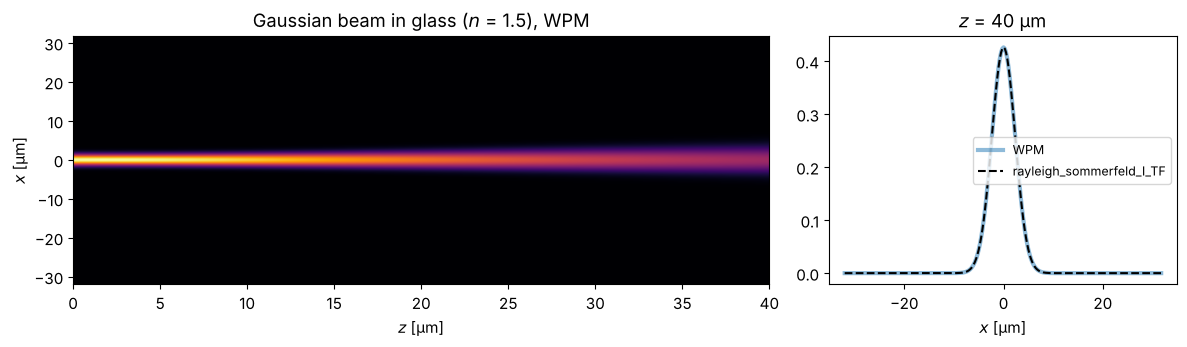

In [2]:
L, N = 64.0, 256
x = grid1d(-L/2, L/2, N)
print(f"dx = {x[1] - x[0]:.3f} µm, max. dx for n = 1.5: {max_sampling_distance(wl, 1.5):.3f} µm")
u0 = np.exp(-x**2/2.0**2)
z_vals = np.linspace(0, 40, 81)
n_glass = lambda X, z: 1.5*np.ones_like(X)

for method in ("direct", "levels"):
    t0 = time.time()
    U_wpm = run_wpm(n_glass, u0, x, z_vals, method=method)
    print(f"80 WPM steps, method='{method}': {time.time() - t0:.3f} s")
y2 = grid1d(-1, 1, 2)    # two y rows: problem invariant in y
U_rs, _, _ = prop.rayleigh_sommerfeld_I_TF(np.tile(u0, (2, 1)).astype(complex), x, y2, z_vals[-1], wl, n=1.5)
print(f"max. deviation from RS: {np.abs(U_wpm[-1] - U_rs[0]).max():.1e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2, 1]})
plot_xz(axes[0], U_wpm, x, z_vals, title="Gaussian beam in glass ($n$ = 1.5), WPM")
axes[1].plot(x, np.abs(U_wpm[-1])**2, lw=3, alpha=0.5, label="WPM")
axes[1].plot(x, np.abs(U_rs[0])**2, "k--", label="rayleigh_sommerfeld_I_TF")
axes[1].set_xlabel("$x$ [µm]"); axes[1].set_title(f"$z$ = {z_vals[-1]:.0f} µm"); axes[1].legend(fontsize=9)
fig.tight_layout()


## 2. Gradient-index (GRIN) lens

A parabolic index profile $n(x) = n_0\,(1 - g^2 x^2/2)$ acts like a continuous
sequence of weak lenses. Rays oscillate sinusoidally about the axis,
$x(z) = x_0\cos(gz)$, with the *pitch length* $P = 2\pi/g$. A Gaussian beam with the
radius $w_m = \sqrt{2/(k_0 n_0 g)}$ is the fundamental mode of the profile and
propagates unchanged. A narrower beam "breathes" with the period $P/2$, an offset
one swings like the ray of geometrical optics. (Shown is $I^{0.6}$, so that the
weak parts stay visible.) The profile is continuous, so almost every pixel has
its own index, and `method="auto"` uses the direct sum here.

The offset beam swings somewhat more slowly than the paraxial ray $x_0\cos(gz)$:
at 8 µm displacement it is no longer strictly paraxial.

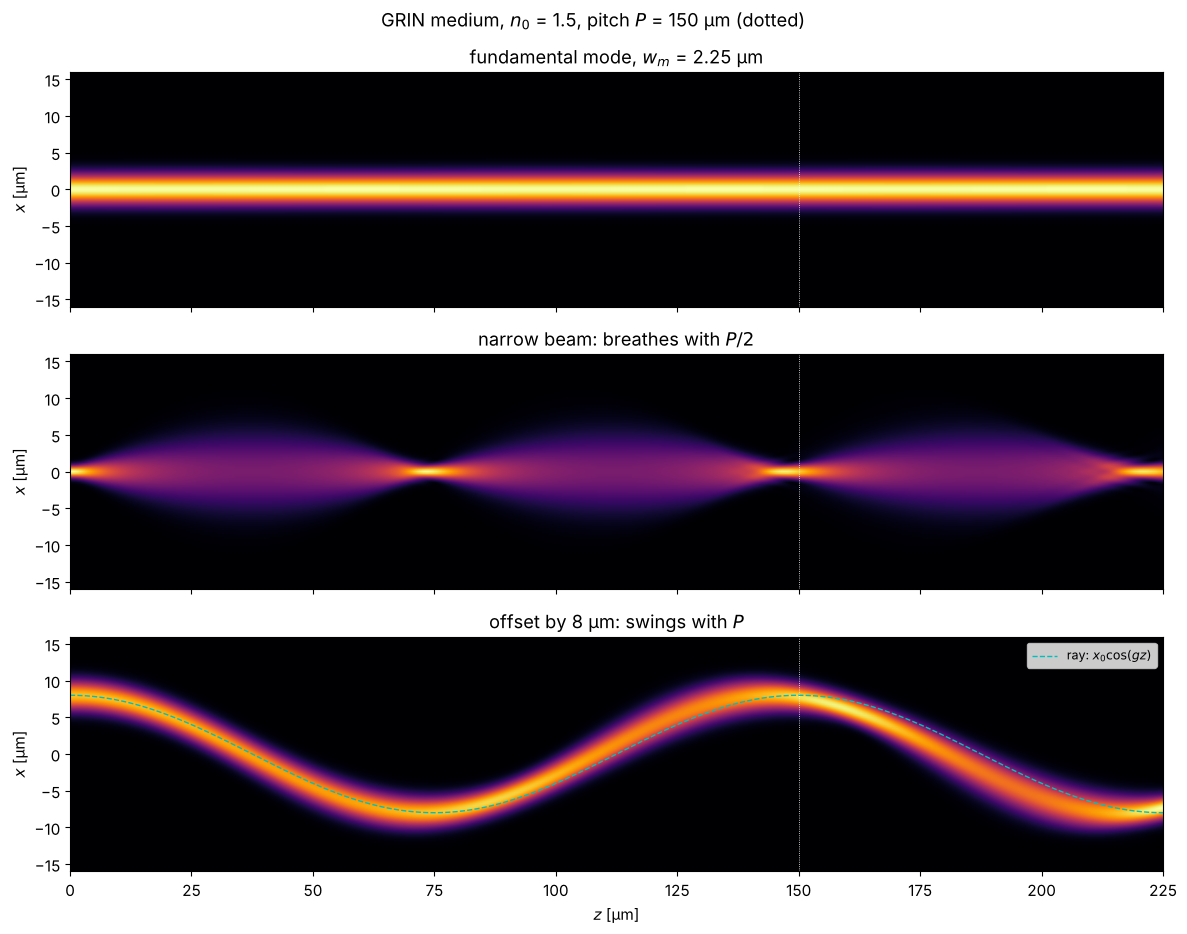

In [3]:
n0, P = 1.5, 150.0
g = 2*np.pi/P
# clip the profile at n = 1.3 near the edge, otherwise the index would drop below 1 at the window edge:
n_grin = lambda X, z: np.maximum(n0*(1 - g**2*X**2/2), 1.3)
w_m = np.sqrt(2/(k0*n0*g))
z_vals = np.linspace(0, 1.5*P, 451)

beams = ((np.exp(-x**2/w_m**2), f"fundamental mode, $w_m$ = {w_m:.2f} µm"),
         (np.exp(-x**2/(w_m/2.5)**2), "narrow beam: breathes with $P/2$"),
         (np.exp(-(x - 8)**2/w_m**2), "offset by 8 µm: swings with $P$"))
fig, axes = plt.subplots(3, 1, figsize=(12, 9.5), sharex=True)
for ax, (u, title) in zip(axes, beams):
    U = run_wpm(n_grin, u, x, z_vals)
    plot_xz(ax, U, x, z_vals, title=title, xlim=(-16, 16), gamma=0.6)
    for m in range(1, 2):
        ax.axvline(m*P, color="w", lw=0.6, ls=":")
axes[2].plot(z_vals, 8*np.cos(g*z_vals), "c--", lw=1, label="ray: $x_0\\cos(gz)$")
axes[2].legend(loc="upper right", fontsize=9)
for ax in axes[:2]:
    ax.set_xlabel("")
fig.suptitle(f"GRIN medium, $n_0$ = {n0}, pitch $P$ = {P:.0f} µm (dotted)")
fig.tight_layout()

## 3. Step-index waveguide

A core with a higher index traps light by total internal reflection. In the wave
picture: the core supports guided modes whose field decays evanescently in the
cladding. A Gaussian beam that does not exactly match the fundamental mode excites
several modes, which travel with different propagation constants and beat against
each other. Without a core (bottom) the beam simply diffracts apart. With two index values,
`method="auto"` uses the fast `"levels"` sum.

NA = 0.344, V parameter (half core width) = 6.49 -> about 5 guided modes


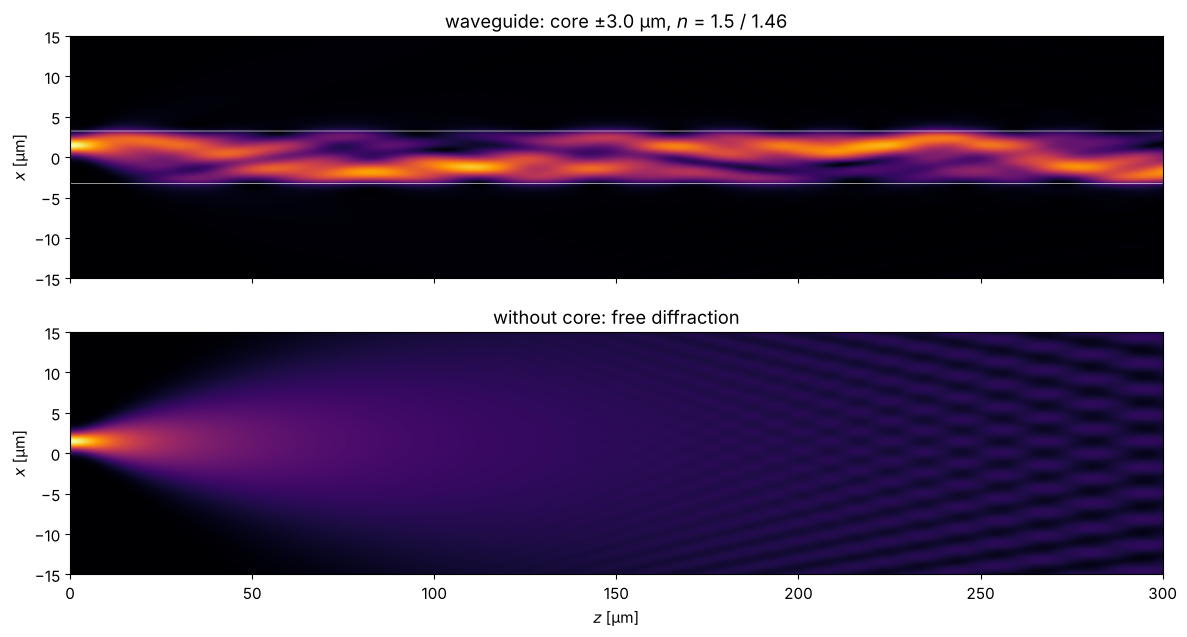

In [4]:
core, n_core, n_clad = 3.0, 1.50, 1.46
n_wg = lambda X, z: np.where(np.abs(X) <= core, n_core, n_clad)
NA_wg = np.sqrt(n_core**2 - n_clad**2)
V = k0*core*NA_wg
print(f"NA = {NA_wg:.3f}, V parameter (half core width) = {V:.2f} -> about {int(2*V/np.pi) + 1} guided modes")
z_vals = np.linspace(0, 300, 601)
u_in = np.exp(-(x - 1.5)**2/1.2**2)   # narrow and slightly offset: excites several modes

U_wg = run_wpm(n_wg, u_in, x, z_vals)
U_free = run_wpm(lambda X, z: n_clad*np.ones_like(X), u_in, x, z_vals)
n_map = np.array([n_wg(x, z) for z in z_vals])

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
plot_xz(axes[0], U_wg, x, z_vals, n_map=n_map, title=f"waveguide: core ±{core} µm, $n$ = {n_core} / {n_clad}",
        xlim=(-15, 15), gamma=0.6)
plot_xz(axes[1], U_free, x, z_vals, title="without core: free diffraction", xlim=(-15, 15), gamma=0.6)
axes[0].set_xlabel("")
fig.tight_layout()

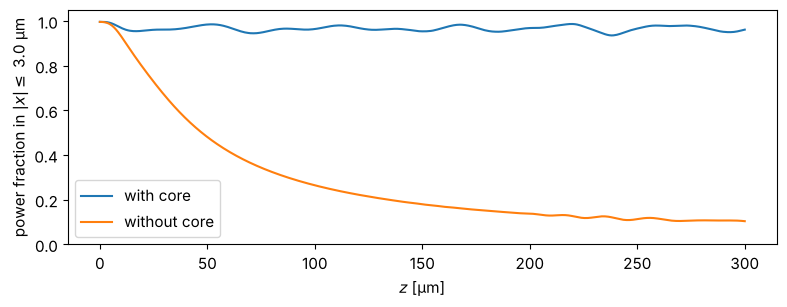

In [5]:
P_core = [np.sum(np.abs(U[np.abs(x) <= core])**2)/np.sum(np.abs(U)**2) for U in U_wg]
P_free = [np.sum(np.abs(U[np.abs(x) <= core])**2)/np.sum(np.abs(U)**2) for U in U_free]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(z_vals, P_core, label="with core")
ax.plot(z_vals, P_free, label="without core")
ax.set_xlabel("$z$ [µm]"); ax.set_ylabel("power fraction in $|x| \\leq$ " + f"{core} µm")
ax.set_ylim(0, 1.05); ax.legend()
fig.tight_layout()

Part of the power is lost at the beginning: it belongs to radiation modes that are
not guided and radiate sideways. (At the window edge, this light re-enters on the
other side because of the periodic boundary conditions of the plane-wave
decomposition. For longer distances, an absorbing index $n + i\kappa$ near the
window edges takes it out.)

## 4. A thick cylindrical lens

Finally, a case the WPM is made for: a large index step at a curved surface. A
plano-convex cylindrical glass lens ($n = 1.5$) with radius of curvature $R$ has the
focal length $f = R/(n-1)$, measured from the principal plane, which for a
plano-convex lens lies at the vertex of the curved surface. With $\pm 30$ µm at
$R = 60$ µm, however, the aperture is anything but paraxial. The WPM shows the
focus including spherical aberration: marginal rays cross the axis too early, the
intensity maximum lies well before the paraxial focus, and a caustic forms in
front of the focus.

699 WPM steps with N = 512: 0.3 s


paraxial focus at z = 135.0 µm, intensity maximum at z = 119.7 µm


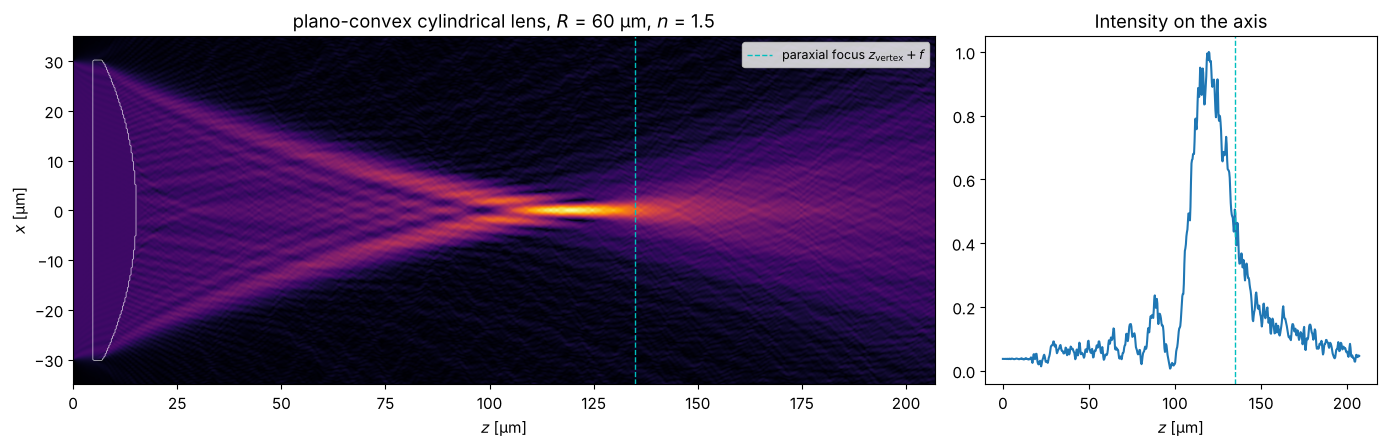

In [6]:
L4, N4 = 96.0, 512
x4 = grid1d(-L4/2, L4/2, N4)
R_lens, n_lens, z_front, half_ap = 60.0, 1.5, 5.0, 30.0
sag = R_lens - np.sqrt(np.maximum(R_lens**2 - x4**2, 0))
t_center = R_lens - np.sqrt(R_lens**2 - half_ap**2) + 2.0   # centre thickness
z_vertex = z_front + t_center   # vertex of the curved back surface

def n_lens_func(X, z):
    # flat front surface at z_front, curved back surface: z <= z_vertex - sag(x)
    s = R_lens - np.sqrt(np.maximum(R_lens**2 - X**2, 0))
    inside = (z >= z_front) & (z <= z_vertex - s) & (np.abs(X) <= half_ap)
    return np.where(inside, n_lens, 1.0)

f = R_lens/(n_lens - 1)
z_vals = np.linspace(0, z_vertex + 1.6*f, 700)
u_plane = np.where(np.abs(x4) <= half_ap, 1.0, 0.0)*np.exp(-(x4/40)**8)  # plane wave with soft edges
t0 = time.time()
U_lens = run_wpm(n_lens_func, u_plane, x4, z_vals)
print(f"{len(z_vals) - 1} WPM steps with N = {N4}: {time.time() - t0:.1f} s")
n_map = np.array([n_lens_func(x4, z) for z in z_vals])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2.2, 1]})
plot_xz(axes[0], U_lens, x4, z_vals, n_map=n_map, title=f"plano-convex cylindrical lens, $R$ = {R_lens:.0f} µm, $n$ = {n_lens}",
        xlim=(-35, 35), gamma=0.5)
axes[0].axvline(z_vertex + f, color="c", ls="--", lw=1, label="paraxial focus $z_\\mathrm{vertex} + f$")
axes[0].legend(loc="upper right", fontsize=9)
I_axis = np.abs(U_lens[:, N4//2])**2
axes[1].plot(z_vals, I_axis/I_axis.max())
axes[1].axvline(z_vertex + f, color="c", ls="--", lw=1)
axes[1].set_xlabel("$z$ [µm]"); axes[1].set_title("Intensity on the axis")
fig.tight_layout()
z_peak = z_vals[np.argmax(I_axis)]
print(f"paraxial focus at z = {z_vertex + f:.1f} µm, intensity maximum at z = {z_peak:.1f} µm")

## Applications

With the fast `"levels"` sum, structures made of a few materials cost only a few
FFTs per step, so devices that are hundreds of wavelengths long run in seconds.
The following sections show some classic applications: integrated optical
components, a fibre, a microlens array and a diffraction grating. Wherever
possible, the WPM is compared with an independent result.

Two helpers first:

- `slab_modes()` finds the guided modes of a $y$-invariant index profile $n(x)$
  with finite differences, i.e. the eigenvalues $\beta^2$ of
  $\partial_x^2 + k_0^2 n(x)^2$. They serve as input fields and as reference.
- `absorber()` adds an absorbing index $i\kappa$ near the window edges, so that
  radiated light does not re-enter on the other side. $\kappa$ increases in a few
  steps instead of smoothly: this keeps the number of distinct index values (and
  the cost of `"levels"`) small.

In [7]:
from scipy.linalg import eigh_tridiagonal

def slab_modes(n_x, x, num=1):
    # largest eigenvalues beta**2 of d²/dx² + k0² n(x)² (second order finite differences)
    dx = x[1] - x[0]
    diag = -2/dx**2 + (k0*n_x)**2
    off = np.ones(len(x) - 1)/dx**2
    beta2, modes = eigh_tridiagonal(diag, off, select="i", select_range=(len(x) - num, len(x) - 1))
    modes = modes[:, ::-1].T
    return np.sqrt(beta2[::-1]), modes/np.sqrt(np.sum(np.abs(modes)**2, axis=1, keepdims=True))

def absorber(X, L, width=8.0, kappa=0.02, steps=4):
    # i*kappa in `steps` steps within `width` from the window edges +-L/2
    depth = np.clip((np.abs(X) - (L/2 - width))/width, 0, 1)
    return 1j*kappa*np.ceil(depth*steps)/steps

def power_in_mode(u, mode):
    # fraction of the power of the (normalized) mode that u carries, |<mode|u>|²
    return np.abs(np.vdot(mode, u))**2

n_core, n_clad = 1.50, 1.46   # e.g. a polymer or doped glass waveguide

## 5. Directional coupler

Two parallel waveguides close to each other exchange power: the evanescent tail of
the mode in one guide excites the other one. In terms of the *supermodes* of the
pair, light launched into one guide is the sum of the even and the odd supermode,
which travel with $\beta_e$ and $\beta_o$. Their beating moves the power completely
into the other guide after the coupling length

$$L_c = \frac{\pi}{\beta_e - \beta_o}, \qquad
  P_\mathrm{right}(z) = \sin^2\!\left(\frac{\pi z}{2 L_c}\right).$$

Couplers like this are the basic building block of integrated optics: a coupler
of length $L_c/2$ is a 3 dB splitter (half the power in each output), and it is
the beam splitter of integrated Mach-Zehnder interferometers and modulators. Here
$\beta_e$, $\beta_o$ come from `slab_modes()` and are compared with the power
transfer computed by the WPM.

coupling length from the supermodes: L_c = 294.0 µm; 1176 WPM steps: 1.4 s
WPM: complete transfer at z = 298.5 µm, 3 dB point (50 %) at z = 149.0 µm (L_c/2 = 147.0 µm)


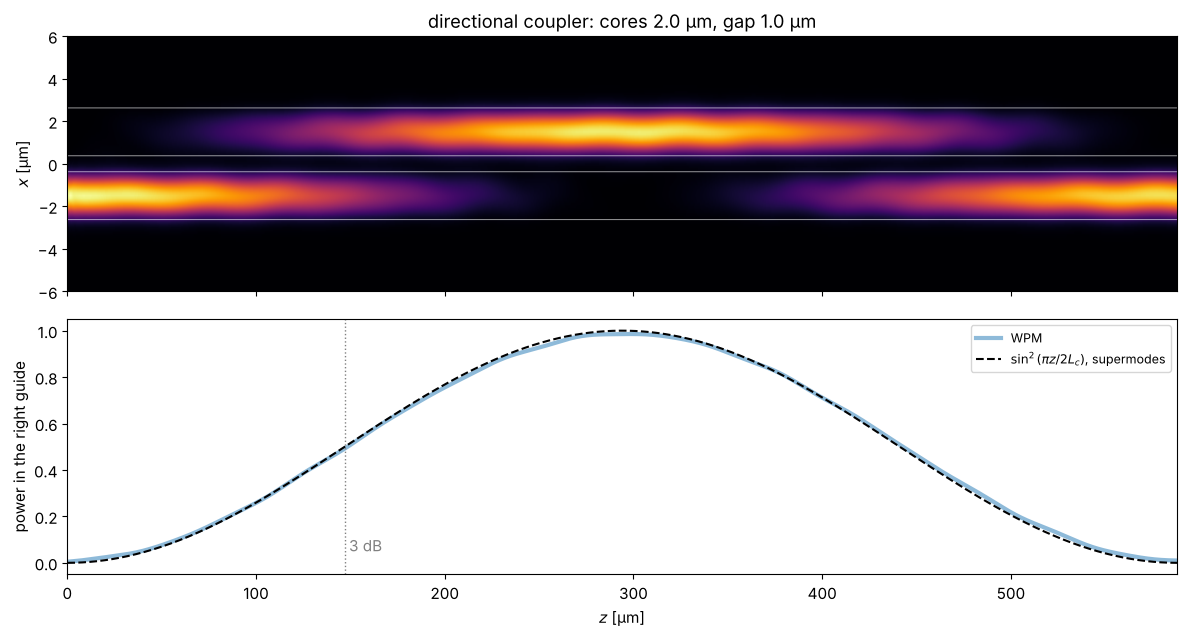

In [8]:
L5, N5 = 64.0, 512
x5 = grid1d(-L5/2, L5/2, N5)
w_wg, gap = 2.0, 1.0
c = (w_wg + gap)/2   # waveguide centres at +-c
n_pair = lambda X: np.where((np.abs(X - c) <= w_wg/2) | (np.abs(X + c) <= w_wg/2), n_core, n_clad)

(beta_e, beta_o), _ = slab_modes(n_pair(x5), x5, num=2)
L_c = np.pi/(beta_e - beta_o)
_, (mode_left,) = slab_modes(np.where(np.abs(x5 + c) <= w_wg/2, n_core, n_clad), x5)

z_vals = np.arange(0, 2*L_c, 0.5)
t0 = time.time()
U_dc = run_wpm(lambda X, z: n_pair(X) + absorber(X, L5), mode_left, x5, z_vals)
print(f"coupling length from the supermodes: L_c = {L_c:.1f} µm; {len(z_vals) - 1} WPM steps: {time.time() - t0:.1f} s")

I = np.abs(U_dc)**2
P_right = I[:, x5 > 0].sum(axis=1)/I.sum(axis=1)
print(f"WPM: complete transfer at z = {z_vals[np.argmax(P_right)]:.1f} µm, "
      f"3 dB point (50 %) at z = {z_vals[np.argmax(P_right >= 0.5)]:.1f} µm (L_c/2 = {L_c/2:.1f} µm)")

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
plot_xz(axes[0], U_dc, x5, z_vals, n_map=np.tile(n_pair(x5), (len(z_vals), 1)),
        title=f"directional coupler: cores {w_wg} µm, gap {gap} µm", xlim=(-6, 6))
axes[0].set_xlabel("")
axes[1].plot(z_vals, P_right, lw=3, alpha=0.5, label="WPM")
axes[1].plot(z_vals, np.sin(np.pi*z_vals/(2*L_c))**2, "k--", label=r"$\sin^2(\pi z/2L_c)$, supermodes")
axes[1].axvline(L_c/2, color="gray", ls=":", lw=1); axes[1].text(L_c/2, 0.05, " 3 dB", color="gray")
axes[1].set_xlabel("$z$ [µm]"); axes[1].set_ylabel("power in the right guide"); axes[1].legend(fontsize=9)
fig.tight_layout()

## 6. Multimode interference (MMI) splitter

A wide multimode section is fed by a single-mode waveguide. The input excites many
modes of the wide section, and since their propagation constants are nearly
quadratic in the mode number, $\beta_0 - \beta_\nu \approx \nu(\nu + 2)\pi/(3L_\pi)$
with the beat length $L_\pi = \pi/(\beta_0 - \beta_1)$, they rephase periodically:
the input field is reproduced as single and multiple *self-images*. For a
centred input, only the symmetric modes are excited and the first two-fold image
lies at

$$L_\mathrm{MMI} = \frac{3 L_\pi}{8}.$$

Two output waveguides at $x = \pm W/4$ pick up the images: a compact, robust
50:50 splitter that is used in most photonic integrated circuits. Scanning the
length shows the tolerance of the design.

L_pi = 582 µm, L_MMI = 3 L_pi/8 = 218.3 µm
outputs: 0.458 / 0.458, excess loss 0.38 dB


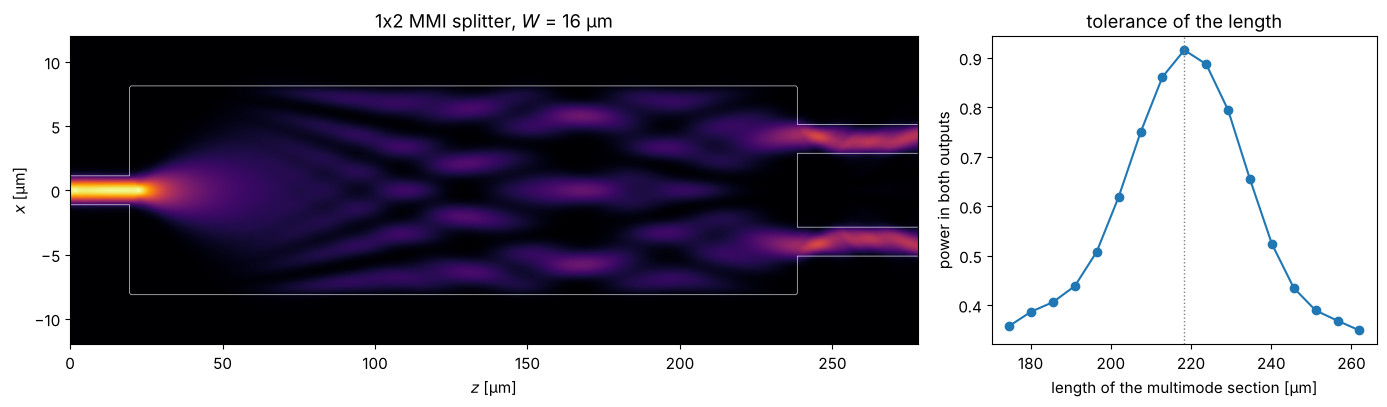

In [9]:
w_in, W_mmi = 2.0, 16.0
(b0, b1), _ = slab_modes(np.where(np.abs(x5) <= W_mmi/2, n_core, n_clad), x5, num=2)
L_pi = np.pi/(b0 - b1)
L_mmi = 3*L_pi/8
_, (mode_in,) = slab_modes(np.where(np.abs(x5) <= w_in/2, n_core, n_clad), x5)
_, (mode_up,) = slab_modes(np.where(np.abs(x5 - W_mmi/4) <= w_in/2, n_core, n_clad), x5)
_, (mode_down,) = slab_modes(np.where(np.abs(x5 + W_mmi/4) <= w_in/2, n_core, n_clad), x5)
z_in = 20.0   # start of the multimode section

def n_mmi(X, z, length=L_mmi):
    if z < z_in:
        core = np.abs(X) <= w_in/2
    elif z <= z_in + length:
        core = np.abs(X) <= W_mmi/2
    else:
        core = (np.abs(X - W_mmi/4) <= w_in/2) | (np.abs(X + W_mmi/4) <= w_in/2)
    return np.where(core, n_core, n_clad) + absorber(X, L5)

def mmi_outputs(length):
    z = np.arange(0, z_in + length + 40, 0.5)
    U = run_wpm(lambda X, zz: n_mmi(X, zz, length), mode_in, x5, z)
    return z, U, power_in_mode(U[-1], mode_up), power_in_mode(U[-1], mode_down)

z_vals, U_mmi, P_up, P_down = mmi_outputs(L_mmi)
print(f"L_pi = {L_pi:.0f} µm, L_MMI = 3 L_pi/8 = {L_mmi:.1f} µm")
print(f"outputs: {P_up:.3f} / {P_down:.3f}, excess loss {-10*np.log10(P_up + P_down):.2f} dB")

lengths = L_mmi*np.linspace(0.8, 1.2, 17)
P_total = [sum(mmi_outputs(l)[2:]) for l in lengths]

n_map = np.array([n_mmi(x5, z).real for z in z_vals])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
plot_xz(axes[0], U_mmi, x5, z_vals, n_map=n_map, title=f"1x2 MMI splitter, $W$ = {W_mmi:.0f} µm", xlim=(-12, 12))
axes[1].plot(lengths, P_total, "o-")
axes[1].axvline(L_mmi, color="gray", ls=":", lw=1)
axes[1].set_xlabel("length of the multimode section [µm]"); axes[1].set_ylabel("power in both outputs")
axes[1].set_title("tolerance of the length")
fig.tight_layout()

## 7. Adiabatic taper (spot size converter)

The mode of a narrow waveguide is much smaller than the mode of a fibre or of a
wide waveguide. A *taper* widens the waveguide gradually. If the width changes
slowly enough (adiabatically), the light stays in the fundamental mode at every
point and arrives in the fundamental mode of the wide guide. An abrupt step
instead excites higher order modes and radiation: the coupling efficiency is
just the overlap of the two modes. This is how edge couplers bring light from a
fibre onto a chip and back.

abrupt step: 0.502 (mode overlap: 0.493)


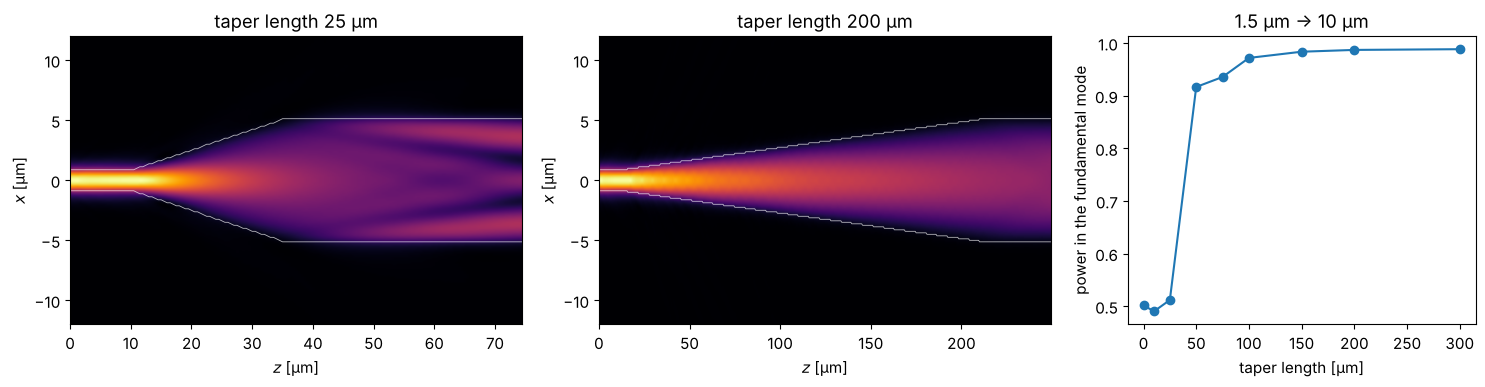

In [10]:
w_narrow, w_wide, z_start = 1.5, 10.0, 10.0
_, (mode_narrow,) = slab_modes(np.where(np.abs(x5) <= w_narrow/2, n_core, n_clad), x5)
_, (mode_wide,) = slab_modes(np.where(np.abs(x5) <= w_wide/2, n_core, n_clad), x5)

def n_taper(X, z, length):
    s = np.clip((z - z_start)/length, 0, 1) if length > 0 else float(z >= z_start)
    width = w_narrow + (w_wide - w_narrow)*s
    return np.where(np.abs(X) <= width/2, n_core, n_clad) + absorber(X, L5)

def taper(length):
    z = np.arange(0, z_start + length + 40, 0.5)
    U = run_wpm(lambda X, zz: n_taper(X, zz, length), mode_narrow, x5, z)
    return z, U, power_in_mode(U[-1], mode_wide)

taper_lengths = [0, 10, 25, 50, 75, 100, 150, 200, 300]
eta = [taper(l)[2] for l in taper_lengths]
print(f"abrupt step: {eta[0]:.3f} (mode overlap: {power_in_mode(mode_narrow, mode_wide):.3f})")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1.3, 1.3, 1]})
for ax, length in zip(axes[:2], (25, 200)):
    z, U, _ = taper(length)
    n_map = np.array([n_taper(x5, zz, length).real for zz in z])
    plot_xz(ax, U, x5, z, n_map=n_map, title=f"taper length {length} µm", xlim=(-12, 12), gamma=0.6)
axes[2].plot(taper_lengths, eta, "o-")
axes[2].set_xlabel("taper length [µm]"); axes[2].set_ylabel("power in the fundamental mode")
axes[2].set_title(f"{w_narrow} µm -> {w_wide:.0f} µm")
fig.tight_layout()

## 8. Step-index fibre: a full 2D cross-section

So far all problems were invariant in $y$. With 2D fields, the WPM propagates
through a fibre with a circular core. The guided LP modes of the weakly guiding
fibre are known semi-analytically (`pyoptics.modes.lp_modes()`); the WPM must
propagate the LP$_{01}$ mode unchanged, with the phase velocity given by its
effective index $n_\mathrm{eff}$. A beam launched off-axis excites LP$_{01}$
and LP$_{11}$, which beat: the spot swings to the other side of the core after
half the beat length $L_B = \lambda/(n_{\mathrm{eff},01} - n_{\mathrm{eff},11})$.
Mode beating like this is the principle of fibre sensors and of the "speckle" of
few-mode fibres.

V = 3.23: LP01 n_eff = 1.448614, LP11 n_eff = 1.446119


WPM: n_eff = 1.448600, power in LP01 after 200 µm: 0.9977


200 WPM steps on 128x128: 1.2 s


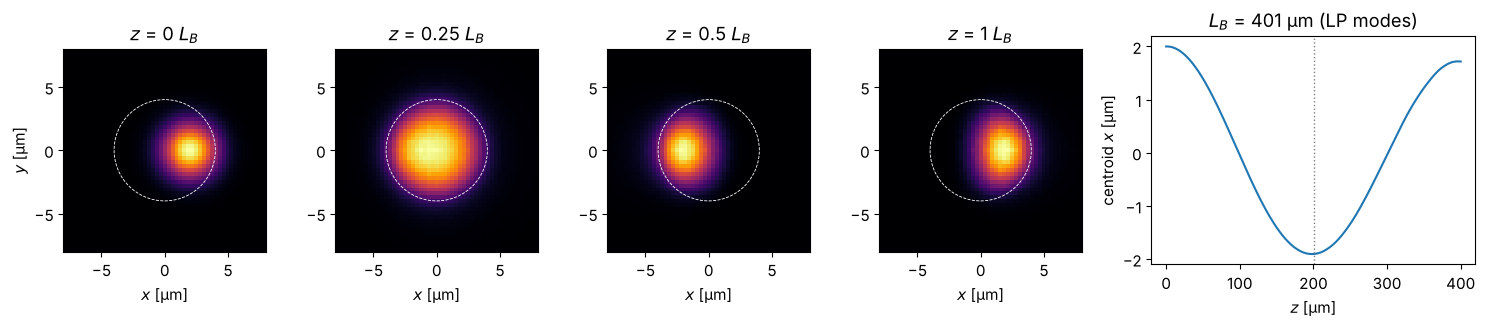

In [11]:
from pyoptics.modes import coupling_efficiency, lp_modes, lp_mode_field
from pyoptics.utils import grid2d

a_core, n1_fib, n2_fib = 4.0, 1.4504, 1.4447
lp01, lp11 = lp_modes(core_radius=a_core, n_core=n1_fib, n_clad=n2_fib, wavelength=wl)
print(f"V = {lp01.V:.2f}: LP01 n_eff = {lp01.n_eff:.6f}, LP11 n_eff = {lp11.n_eff:.6f}")

L8, N8 = 40.0, 128
x8, y8, X8, Y8 = grid2d(-L8/2, L8/2, -L8/2, L8/2, N8, assume_periodicity=True)
n_fibre = lambda X, Y, z: np.where(X**2 + Y**2 <= a_core**2, n1_fib, n2_fib)

# LP01 propagates unchanged; its phase (relative to the cladding) gives n_eff:
u01 = lp_mode_field(lp01, x8, y8, a_core)
z_vals = np.arange(0, 201, 2.0)
U01 = wpm_propagate_z(n_fibre, u01, x8, y8, z_vals, wl)
c01 = np.array([np.vdot(u01, u) for u in U01])
slope = np.polyfit(z_vals, np.unwrap(np.angle(c01*np.exp(-1j*k0*n2_fib*z_vals))), 1)[0]
print(f"WPM: n_eff = {n2_fib + slope/k0:.6f}, power in LP01 after {z_vals[-1]:.0f} µm: "
      f"{coupling_efficiency(U01[-1], u01, x8, y8):.4f}")

# off-axis launch: LP01 and LP11 beat
L_B = wl/(lp01.n_eff - lp11.n_eff)
z_vals = np.arange(0, L_B + 1, 2.0)
t0 = time.time()
U_off = wpm_propagate_z(n_fibre, np.exp(-((X8 - 2.0)**2 + Y8**2)/3.0**2), x8, y8, z_vals, wl)
print(f"{len(z_vals) - 1} WPM steps on {N8}x{N8}: {time.time() - t0:.1f} s")
I = np.abs(U_off)**2
x_centroid = np.sum(I*X8, axis=(1, 2))/np.sum(I, axis=(1, 2))

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.6]})
for ax, frac in zip(axes, (0, 0.25, 0.5, 1.0)):
    k = np.argmin(np.abs(z_vals - frac*L_B))
    ax.imshow(I[k], extent=(x8[0], x8[-1], y8[0], y8[-1]), cmap="inferno")
    ax.add_patch(plt.Circle((0, 0), a_core, fill=False, color="w", lw=0.6, ls="--"))
    ax.set_xlim(-8, 8); ax.set_ylim(-8, 8); ax.set_title(f"$z$ = {frac:g} $L_B$")
    ax.set_xlabel("$x$ [µm]")
axes[0].set_ylabel("$y$ [µm]")
axes[4].plot(z_vals, x_centroid)
axes[4].axvline(L_B/2, color="gray", ls=":", lw=1)
axes[4].set_xlabel("$z$ [µm]"); axes[4].set_ylabel("centroid $x$ [µm]")
axes[4].set_title(f"$L_B$ = {L_B:.0f} µm (LP modes)")
fig.tight_layout()

## 9. Microlens array and Talbot self-imaging

An array of plano-convex cylindrical microlenses (pitch $p$, radius of curvature
$R$) focuses a plane wave into a row of foci at $f = R/(n - 1)$ behind the curved
surfaces. Microlens arrays are used in beam homogenizers, Shack-Hartmann sensors
(notebook 25) and in front of image sensors. The periodic window of the WPM is
convenient here: it represents an infinite array.

Any periodic field reproduces itself after the *Talbot length*
$z_T \approx 2p^2/\lambda$: the foci reappear near $f + z_T$ and, shifted by
half a pitch, near $f + z_T/2$; in between lie fractional images. (Strictly,
the self-images are exact only in the paraxial limit; the formula
$z_T = \lambda/(1 - \sqrt{1 - \lambda^2/p^2})$ used below is exact for the
first harmonic.) The "Talbot carpet" causes crosstalk behind lenslet arrays,
and Talbot illuminators use it on purpose. The foci are long: the depth of
focus $\approx \lambda/\mathrm{NA}^2$ of these small lenses is comparable to $f$.

1011 WPM steps: 0.5 s; f = 20 µm, z_T = 199.5 µm (2p²/λ = 200 µm)
first focus at z = 20.5 µm (vertex + f = 21.3 µm)


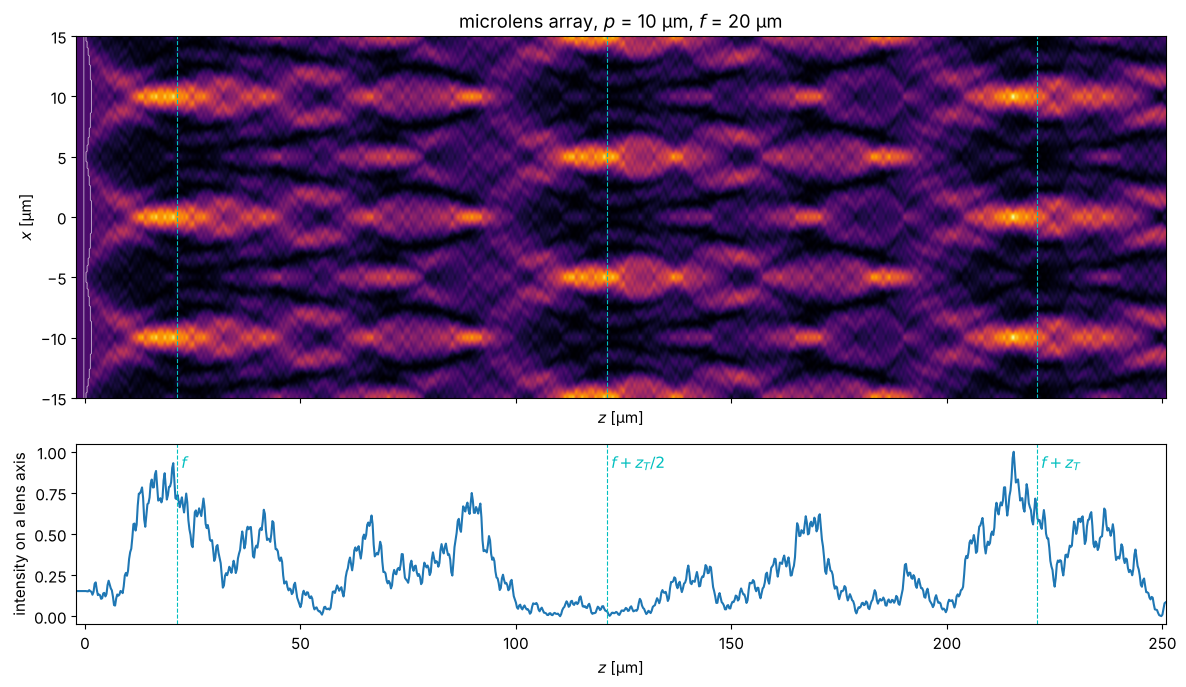

In [12]:
pitch, R_ml, n_ml, n_lenslets = 10.0, 10.0, 1.5, 6
f_ml = R_ml/(n_ml - 1)
L9 = n_lenslets*pitch
x9 = grid1d(-L9/2, L9/2, 768)
t_ml = R_ml - np.sqrt(R_ml**2 - (pitch/2)**2)   # sag at the lenslet edges

def n_mla(X, z):
    x_local = (X + pitch/2) % pitch - pitch/2   # coordinate within each lenslet
    sag = R_ml - np.sqrt(R_ml**2 - x_local**2)
    return np.where((z >= 0) & (z <= t_ml - sag), n_ml, 1.0)

z_T = wl/(1 - np.sqrt(1 - (wl/pitch)**2))
z_vals = np.arange(-2, t_ml + f_ml + 1.15*z_T, 0.25)
t0 = time.time()
U_mla = run_wpm(n_mla, np.ones_like(x9), x9, z_vals)
print(f"{len(z_vals) - 1} WPM steps: {time.time() - t0:.1f} s; f = {f_ml:.0f} µm, z_T = {z_T:.1f} µm (2p²/λ = {2*pitch**2/wl:.0f} µm)")
I_axis = np.abs(U_mla[:, np.argmin(np.abs(x9))])**2
near = z_vals < t_ml + 1.5*f_ml
print(f"first focus at z = {z_vals[near][np.argmax(I_axis[near])]:.1f} µm (vertex + f = {t_ml + f_ml:.1f} µm)")

n_map = np.array([n_mla(x9, z) for z in z_vals])
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
plot_xz(axes[0], U_mla, x9, z_vals, n_map=n_map, title=f"microlens array, $p$ = {pitch:.0f} µm, $f$ = {f_ml:.0f} µm",
        xlim=(-1.5*pitch, 1.5*pitch), gamma=0.8)
axes[1].plot(z_vals, I_axis/I_axis.max())
for ax in axes:
    for z_mark, label in ((t_ml + f_ml, "$f$"), (t_ml + f_ml + z_T/2, "$f + z_T/2$"), (t_ml + f_ml + z_T, "$f + z_T$")):
        ax.axvline(z_mark, color="c", ls="--", lw=0.8)
        if ax is axes[1]:
            ax.text(z_mark, 0.9, " " + label, color="c")
axes[1].set_xlabel("$z$ [µm]"); axes[1].set_ylabel("intensity on a lens axis")
fig.tight_layout()

## 10. Diffraction gratings: beyond the thin element approximation

Diffractive optical elements are usually designed with the *thin element
approximation* (TEA): the element multiplies the field by
$e^{i k_0 n(x) d}$. A binary glass grating of depth $d = \lambda/(2(n - 1))$ and
duty cycle 1/2 is then a $\pi$ phase grating with no zeroth order and
$4/\pi^2 \approx 40.5\,\%$ in each first order. For periods of a few wavelengths,
light inside the ridges "sees" the sidewalls and the TEA fails.

The WPM propagates through the grating profile slice by slice and captures most
of this. The reference is the rigorous coupled wave analysis
(`pyoptics.litho.rcwa`, TE polarization: $E$ along the grooves, the scalar case).
The efficiencies are normalized to the transmitted power, because the scalar
methods ignore reflections. The TEA misses the zeroth order and overestimates
the first orders already at periods of $10\lambda$. The WPM follows RCWA down to
periods of about $3\lambda$ and roughly down to $2\lambda$; below, the scalar
picture breaks down and only RCWA is reliable.

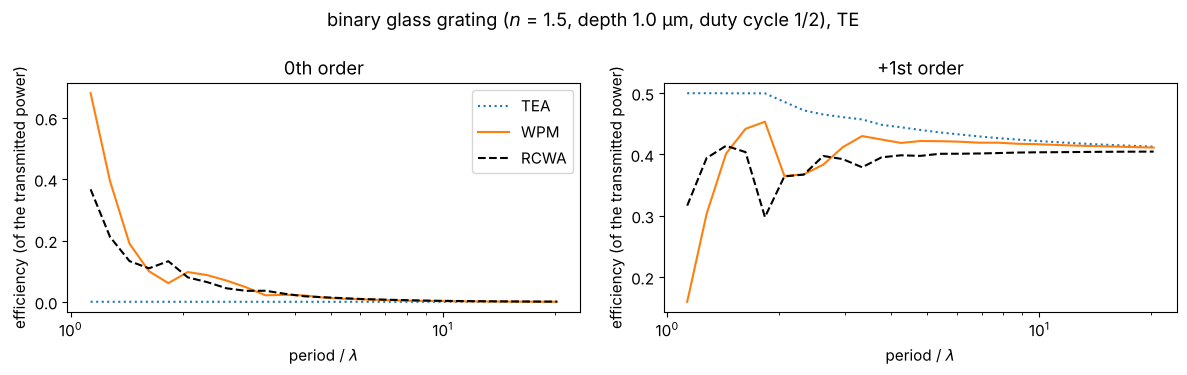

In [13]:
from pyoptics.litho.rcwa import rcwa, Layer

n_gr = 1.5
depth = wl/(2*(n_gr - 1))

def order_efficiencies(field, period, n_out):
    # power flux of the propagating orders, normalized to the transmitted power
    m = np.rint(np.fft.fftfreq(len(field), 1/len(field))).astype(int)
    kz = np.sqrt(complex(1)*((n_out*k0)**2 - (2*np.pi*m/period)**2))
    flux = np.abs(np.fft.fft(field))**2*np.where(np.abs(kz.imag) < 1e-12, kz.real, 0)
    flux = flux/flux.sum()
    return flux[m == 0][0], flux[m == 1][0]

periods = np.geomspace(1.13, 20.3, 25)
eta = {"TEA": [], "WPM": [], "RCWA": []}
for period in periods:
    xg = (np.arange(128) - 64)*period/128
    ridge = np.abs(xg) < period/4
    # plane wave from air through the ridges (z = 0..depth) into the glass substrate:
    u = wpm_propagate_z(lambda X, Y, z: np.where(np.abs(X) < period/4, n_gr, 1.0), np.ones(128, complex),
                        xg, None, np.linspace(0, depth, 41), wl)[-1]
    eta["WPM"].append(order_efficiencies(u, period, n_gr))
    eta["TEA"].append(order_efficiencies(np.exp(1j*k0*np.where(ridge, n_gr, 1.0)*depth), period, n_gr))
    with np.errstate(divide="ignore", invalid="ignore"):
        res = rcwa(period, [Layer(depth, 1.0, [(0.0, period/2, n_gr)])], wl, n_in=1.0, n_out=n_gr, n_orders=40)
        _, T = res.efficiencies((0, 1))   # TE: E_y
    T = T[0]/T[0].sum()
    eta["RCWA"].append((T[res.m == 0][0], T[res.m == 1][0]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for name, style in (("TEA", ":"), ("WPM", "-"), ("RCWA", "k--")):
    e = np.array(eta[name])
    axes[0].plot(periods/wl, e[:, 0], style, label=name)
    axes[1].plot(periods/wl, e[:, 1], style, label=name)
for ax, title in zip(axes, ("0th order", "+1st order")):
    ax.set_xscale("log"); ax.set_xlabel(r"period / $\lambda$"); ax.set_title(title)
    ax.set_ylabel("efficiency (of the transmitted power)")
axes[0].legend()
fig.suptitle(f"binary glass grating ($n$ = {n_gr}, depth {depth:.1f} µm, duty cycle 1/2), TE")
fig.tight_layout()

## 11. Limits

The WPM is a scalar method. It neglects reflections and polarization, and at
sharp index steps it does not conserve power exactly: the local plane wave sum
is not a unitary operation. In waveguides, where the light meets the core
boundary over and over, this shows up as a slow drift of the power. The check
below propagates the fundamental mode of straight guides: the drift is largest
for narrow, strongly confined cores, its size and even its sign depend on the
step $\Delta z$, and it does not vanish for $\Delta z \to 0$. In the examples
above (step 0.5 µm), the losses of the narrow guides are partly this numerical
loss, e.g. a part of the excess loss of the MMI. Wide guides and smooth
(GRIN) profiles are not affected.

For high index contrast (silicon photonics), sub-wavelength structures or
polarization dependent problems, a full-vector method (RCWA, FDTD, vectorial
mode solvers) is the right tool. The WPM is excellent for weakly guiding
structures, lenses, gradient index media and moderately thick diffractive
elements.


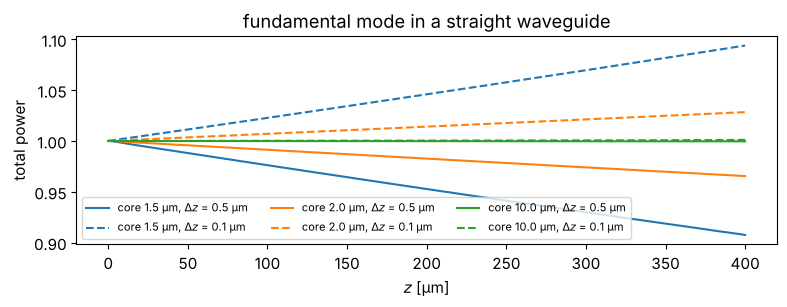

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for width, color in ((1.5, "C0"), (2.0, "C1"), (10.0, "C2")):
    n_x = np.where(np.abs(x5) <= width/2, n_core, n_clad)
    _, (mode,) = slab_modes(n_x, x5)
    for dz, ls in ((0.5, "-"), (0.1, "--")):
        z_vals = np.arange(0, 400 + dz/2, dz)
        U = run_wpm(lambda X, z: n_x, mode, x5, z_vals)
        ax.plot(z_vals, np.sum(np.abs(U)**2, axis=1), ls, color=color,
                label=f"core {width} µm, $\\Delta z$ = {dz} µm")
ax.set_xlabel("$z$ [µm]"); ax.set_ylabel("total power"); ax.legend(fontsize=8, ncol=3, loc="lower left")
ax.set_title("fundamental mode in a straight waveguide")
fig.tight_layout()
